# Fig. S24: decidual-zone module scores, mouse, 3.5 dpi

Reads the final mouse object, scores the 11 microenvironment gene sets of Li et al. (2022) in every nucleus of the 3.5 dpi section with AUCell, draws S24B (the six modules of focus on the section) and S24A (their mean per fibroblast/decidual subtype), and writes the per-nucleus scores as a CSV. No nucleus is removed.

The scoring is the one the Methods describe (*Decidual zone module scoring*):

1. **Genes ranked.** Genes detected (count > 0) in at least 1% of the nuclei of the **whole** object, plus the Table 1 genes below that threshold that are still detected in at least one nucleus. The threshold is taken over all nuclei, not over the 3.5 dpi subset, so the whole object is read before it is subset.
2. **AUCell** (pySCENIC 0.12.1) on raw counts (`layers['counts']`): unweighted gene sets, AUC threshold 0.05 (the AUC covers the top 5% of each nucleus's ranking), seed 0 for the order of genes with equal counts. Each nucleus is ranked on its own, so scoring only the 3.5 dpi nuclei gives exactly the scores they would get in a run over all nuclei.

Display: S24B colours each module from 0 to its 99th percentile among the plotted nuclei; S24A colours each subtype mean from 0 to the module's 99th percentile among the fibroblast and decidual nuclei.

Kernel `rsc_uv`; about 16 GB of memory and 3 minutes on 8 cores. The last section checks the scores against the object's stored `auc_*` columns and the published S24 scores, and lists the numbers the Methods quote.

In [1]:
OBJECT = "/n/netscratch/eddy_lab/Everyone/nhilgert/final_objects/Cevrim_XMens_All_Cells.h5ad"
TIMEPOINT = "3.5_dpi"  # the 3 dpi section, under the release's timepoint names
OUT_DIR = "/n/lab_storage/eddy_lab/users/nhilgert/xmens_scripts/zone_modules/zone_modules_S24"  # None writes nothing
FORCE = False  # overwrite existing outputs in OUT_DIR

# Scores to check against; None skips that check.
RECORD_SCORES = ("/n/lab_storage/eddy_lab/users/nhilgert/xmens_figures/2026-10-30_revision_panels/"
                 "S24_pregnancy_zone_modules/final_object_2026-11-02/data/scores/zone_aucell.csv")
SEED_CHECK = True  # also score with seed 1 for the seed agreement the Methods quote (about 1 more minute)
WORKERS = 8

In [2]:
import hashlib
import json
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from anndata.io import read_elem
from ctxcore.genesig import GeneSignature
from IPython.display import display
from matplotlib import font_manager
from pyscenic.aucell import aucell4r, create_rankings
from scipy.stats import spearmanr

## Settings

In [3]:
GENE_SETS = {  # Li et al. 2022 (Biol Reprod 107:529), Table 1: top 20 markers per microenvironment, in order
    'MMy': ['Actg2', 'Acta2', 'Myl9', 'Myh11', 'Tpm2', 'Pcp4', 'Col3a1', 'Tagln', 'Cnn1', 'Postn', 'Mylk', 'Col6a3', 'Hba-a2', 'Acta1', 'Ifi27l2a', 'Fn1', 'Lum', 'Hbb-bs', 'Col1a2', 'Tpm1'],
    'MD': ['Gzmf', 'Spp1', 'Gzmd', 'Gzme', 'Gzmg', 'Gzmc', 'Gzma', 'Prf1', 'Gzmb', 'Fcer1g', 'Ifitm1', 'AW112010', 'Tyrobp', 'Il2rb', 'Cd52', 'Tmsb15a', 'Chn1', 'Rac2', 'Ptn', 'Trbc1'],
    'VSZ': ['Stmn2', 'Hmgn5', 'Fmo1', 'Wnt6', 'Rcn1', 'Hmgcs2', 'Tdo2', 'Sned1', 'Ntrk1', 'Ear2', 'Tac2', 'Susd2', 'Anxa5', 'Fbn1', 'Srgn', 'Ptn', 'Cxcl14', 'Efemp1', 'Tmem176a', 'Syt13'],
    'FMI': ['S100a8', 'Srd5a1', 'Tfpi', 'Mrgprg', 'Bco1', '2610528A11Rik', 'Angpt2', 'Tmem45a', 'Il1r2', 'Csf1r', 'Timp3', '4930486L24Rik', 'Lmcd1', 'Masp1', 'Lgals3', 'Slc6a12', 'Ramp3', 'Ctsk', 'Cryaa', 'Txn1'],
    'C': ['H19', 'Prl3d1', 'Ceacam15', 'Prl4a1', 'Ceacam9', 'Plet1', 'Prl7a1', 'Pfpl', 'Cts7', 'Mmp9', 'Adm', 'Psg29', 'Krt8', 'Plac1', 'Prl8a9', 'Efna1', 'Jaml', 'Krt18', 'Apoc2', 'Prl2a1'],
    'PDZ': ['Prl3c1', 'Htra1', 'Fabp4', 'Prl8a2', 'Tnnc1', 'Gm2694', 'Dbi', 'Gm2a', 'Psap', 'Cryab', 'Erv3', 'Ctla2b', 'Crct1', 'Adamts5', 'Acsbg1', 'Krtdap', 'Smpd1', 'Gng11', 'Ntn5', 'Hopx'],
    'TDZ': ['Psca', 'Sprr2h', 'Gpnmb', 'Erv3', 'Krtdap', 'Prl8a2', 'Fabp4', 'Olr1', 'Psap', 'Akr1b3', 'Prdx6', 'Rgcc', 'Acsbg1', 'Hsd11b1', 'Dbi', 'Hopx', 'Cyb5a', 'Lipg', 'Ehd3', 'Dnaja4'],
    'SDZ': ['Mt3', 'Mt4', 'Gatm', 'Mgp', 'Coch', 'Dio3', 'Sfrp5', 'Pdzk1ip1', 'Dmkn', 'Mt2', 'Atoh8', 'Anxa8', 'Mt1', 'Nampt', 'Prrx2', 'Tdo2', 'Drd4', 'A2m', 'Prkg2', 'Ass1'],
    'udStr': ['Sfrp4', 'Rbp4', 'Igfbp5', 'Igfbp3', 'Penk', 'Spink8', 'Prxl2a', 'C3', 'Mt4', 'Ctla2a', 'Mfap4', 'Bgn', 'Itm2a', 'Col1a2', 'Igf1', 'Rnase4', 'Col1a1', 'Hsd11b2', 'Serpine2', 'Pcolce'],
    'Glan': ['Prss29', 'Spink1', 'Prss28', 'Prap1', 'Clu', 'Fxyd3', 'Lcn2', 'Wfdc2', 'S100g', 'Tmem213', 'Prom1', 'Mmp7', 'Aqp8', 'Rbp4', 'Cldn10', 'Hp', 'Ier3', 'Sfrp4', 'Klk1', 'Agr2'],
    'AMMy': ['Cnn1', 'Tagln', 'Myl9', 'Myh11', 'Prss29', 'Smtn', 'Igfbp6', 'Acta2', 'Prss28', 'Csrp1', 'Pcp4', 'Tpm2', 'Igfbp2', 'Apoe', 'Flna', 'Ltbp4', 'Actg2', 'Nppa', 'Sparcl1', 'Spink1'],
}
FOCUS = ["PDZ", "TDZ", "SDZ", "VSZ", "MD", "udStr"]  # the modules of S24

AUC_THRESHOLD = 0.05  # pySCENIC default
SEED = 0
GENE_FILTER_FRAC = 0.01  # rank genes detected in >= 1% of the whole object's nuclei, as for the regulon activities
CHUNK = 8000  # nuclei ranked at a time (exact: each nucleus is ranked on its own)

FIBROBLAST_SUBTYPES = ["eFib1", "eFib2", "eFib2i", "eFib3", "eFibP"]  # pooled into one heatmap row
DECIDUAL_SUBTYPES = ["dec1", "dec2", "dec3"]  # one heatmap row each; decAp (apoptotic) is not a row
DROP_APOPTOTIC_IN_MAPS = True  # as published: decAp nuclei are not drawn in S24B
ROTATION_DEG = 135  # display only: counter-clockwise, about the median position of the plotted nuclei
Q = 0.99  # colour ceiling: each module's 99th percentile
CMAP = "magma"

## Load

The obs table and the raw counts of every nucleus: the whole object decides which genes are ranked.

In [4]:
def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 24), b""):
            h.update(block)
    return h.hexdigest()


with h5py.File(OBJECT, "r") as f:
    obs = read_elem(f["obs"])
    var_names = pd.Index(np.asarray(read_elem(f["var"][f["var"].attrs["_index"]])).astype(str))
    g = f["layers/counts"]
    n_obs, n_vars = (int(x) for x in g.attrs["shape"])
    X = sp.csr_matrix((g["data"][()], g["indices"][()], g["indptr"][()]), shape=(n_obs, n_vars))
obs.index = obs.index.astype(str)
assert len(obs) == n_obs and len(var_names) == n_vars and obs.index.is_unique and var_names.is_unique
object_sha256 = sha256(OBJECT)
print(f"{Path(OBJECT).name}: {n_obs:,} nuclei x {n_vars:,} genes, sha256 {object_sha256[:12]}...")
obs["timepoint"].astype(str).value_counts()

Cevrim_XMens_All_Cells.h5ad: 57,033 nuclei x 33,698 genes, sha256 de53189f98c3...


timepoint
uninduced           16569
1.5_dpi_late        13094
3.5_dpi             12324
4.5_dpi_bleeding     7734
2.5_dpi              4170
1.5_dpi_early        3142
Name: count, dtype: int64

## Genes ranked

Decided on all nuclei of the object. The Table 1 genes that the 1% rule drops but that are still detected are added back: without them most markers of rare populations would go (for example 15 of the 20 MD genes), and pySCENIC scores a gene set as all zeros, with only a log warning, when fewer than 80% of its genes are ranked.

In [5]:
min_cells = max(1, int(round(GENE_FILTER_FRAC * n_obs)))
cells_per_gene = np.bincount(X.indices[X.data > 0], minlength=n_vars)  # nuclei with count > 0, per gene
by_rule = cells_per_gene >= min_cells
in_sets = var_names.isin(sorted({gene for genes in GENE_SETS.values() for gene in genes}))
detected_set_genes = in_sets & (cells_per_gene >= 1)
rank_mask = by_rule | detected_set_genes
ranked = var_names[rank_mask]  # in object order
added = list(var_names[detected_set_genes & ~by_rule])
never_detected = list(var_names[in_sets & (cells_per_gene == 0)])

present = {m: [gene for gene in genes if gene in var_names] for m, genes in GENE_SETS.items()}
not_in_annotation = {m: [gene for gene in genes if gene not in var_names] for m, genes in GENE_SETS.items()}
not_in_annotation = {m: genes for m, genes in not_in_annotation.items() if genes}
share_ranked = {m: float(np.isin(present[m], ranked).mean()) for m in GENE_SETS}
assert min(share_ranked.values()) >= 0.8, share_ranked  # pySCENIC would return all-zero scores below 80%
rank_cutoff = int(round(AUC_THRESHOLD * len(ranked)))
print(f"genes with count > 0 in >= {min_cells} of {n_obs:,} nuclei: {by_rule.sum():,}; plus {len(added)} Table 1 genes "
      f"below that = {len(ranked):,} genes ranked; the AUC covers the top {rank_cutoff}")
print("Table 1 genes never detected (not ranked):", never_detected, "| not in the annotation:", not_in_annotation)

genes with count > 0 in >= 570 of 57,033 nuclei: 14,861; plus 42 Table 1 genes below that = 14,903 genes ranked; the AUC covers the top 745
Table 1 genes never detected (not ranked): ['Prl2a1', 'Prl4a1', 'Cts7'] | not in the annotation: {'FMI': ['2610528A11Rik']}


## AUCell on the 3.5 dpi nuclei

In [6]:
keep = np.flatnonzero((obs["timepoint"].astype(str) == TIMEPOINT).to_numpy())
names = obs.index[keep]
Xs = X[keep].astype(np.float32).tocsr()[:, np.flatnonzero(rank_mask)].tocsr()
detected = np.asarray((Xs > 0).sum(axis=1)).ravel()
share_below = float((detected < rank_cutoff).mean())
print(f"{len(names):,} nuclei at {TIMEPOINT}; {share_below:.1%} detect fewer ranked genes than the {rank_cutoff}-gene window")

signatures = [GeneSignature(name=m, gene2weight=present[m]) for m in GENE_SETS]


def aucell(seed):
    parts = []
    for i in range(0, len(names), CHUNK):
        j = min(i + CHUNK, len(names))
        ranks = create_rankings(pd.DataFrame(Xs[i:j].toarray(), index=names[i:j], columns=ranked), seed)
        parts.append(aucell4r(ranks, signatures, AUC_THRESHOLD, False, False, WORKERS))
    result = pd.concat(parts).reindex(names)
    result.columns = [f"auc_{c}" for c in result.columns]
    return result[[f"auc_{m}" for m in GENE_SETS]]


scores = aucell(SEED)
assert scores.notna().all().all()
scores.describe().loc[["mean", "50%", "max"]].round(3)

12,324 nuclei at 3.5_dpi; 9.5% detect fewer ranked genes than the 745-gene window


,auc_MMy,auc_MD,auc_VSZ,auc_FMI,auc_C,auc_PDZ,auc_TDZ,auc_SDZ,auc_udStr,auc_Glan,auc_AMMy
mean,0.033,0.012,0.064,0.039,0.003,0.042,0.038,0.105,0.059,0.013,0.010
50%,0.000,0.000,0.048,0.002,0.000,0.000,0.000,0.091,0.044,0.000,0.000
max,0.515,0.263,0.341,0.474,0.134,0.587,0.446,0.464,0.349,0.196,0.402


In [7]:
seed_rho = None
if SEED_CHECK:  # the order of tied genes is the only random choice
    scores_seed1 = aucell(SEED + 1)
    seed_rho = {m: round(float(spearmanr(scores[f"auc_{m}"], scores_seed1[f"auc_{m}"]).correlation), 3) for m in FOCUS}
    print(f"seed {SEED} vs {SEED + 1}, Spearman rho over the {len(names):,} nuclei:", seed_rho)

seed 0 vs 1, Spearman rho over the 12,324 nuclei: {'PDZ': 0.935, 'TDZ': 0.945, 'SDZ': 0.989, 'VSZ': 0.969, 'MD': 0.94, 'udStr': 0.974}


## Per-nucleus table

One row per nucleus of the section: what the figures draw, plus all 11 module scores. Written to `OUT_DIR` as `S24_zone_module_scores_3.5dpi.csv`.

In [8]:
table = obs.loc[names, ["sample", "timepoint", "cell_type", "cell_subtype", "x_um_qc", "y_um_qc"]].astype(
    {c: str for c in ["sample", "timepoint", "cell_type", "cell_subtype"]}).join(scores)
table.index.name = "barcode"
tag = TIMEPOINT.replace("_", "")
out = Path(OUT_DIR) if OUT_DIR else None


def save_path(name):
    """A path in OUT_DIR; refuses to overwrite an earlier output unless FORCE."""
    path = out / name
    if path.exists() and not FORCE:
        raise FileExistsError(f"{path} exists; set FORCE = True to overwrite")
    return path


if out:
    out.mkdir(parents=True, exist_ok=True)
    table.to_csv(save_path(f"S24_zone_module_scores_{tag}.csv"))
print(f"{len(table):,} nuclei, {int(table['x_um_qc'].notna().sum()):,} with a position")
table.head()

12,324 nuclei, 7,710 with a position


,sample,timepoint,cell_type,cell_subtype,x_um_qc,y_um_qc,auc_MMy,auc_MD,auc_VSZ,auc_FMI,auc_C,auc_PDZ,auc_TDZ,auc_SDZ,auc_udStr,auc_Glan,auc_AMMy
barcode,,,,,,,,,,,,,,,,,
TATCCTACATACAGAA-1-3_dpi_mck10a,3.5_dpi_mck10a,3.5_dpi,decidual_cell,dec3,NaN,NaN,0.00000,0.0,0.000000,0.027623,0.000000,0.173893,0.177450,0.226376,0.000000,0.0,0.0
ACTATTCGTATTGACC-1-3_dpi_mck10a,3.5_dpi_mck10a,3.5_dpi,decidual_cell,dec2,NaN,NaN,0.00000,0.0,0.048188,0.013140,0.000000,0.043691,0.049262,0.254362,0.047114,0.0,0.0
GATGCTACATAGGCGA-1-3_dpi_mck10a,3.5_dpi_mck10a,3.5_dpi,decidual_cell,dec3,NaN,NaN,0.00651,0.0,0.020537,0.292759,0.056771,0.302483,0.155503,0.090604,0.045302,0.0,0.0
CCATCACAGCAGGCAT-1-3_dpi_mck10a,3.5_dpi_mck10a,3.5_dpi,decidual_cell,dec3,5626.873832,3193.441805,0.00000,0.0,0.000000,0.015542,0.000000,0.230604,0.240268,0.220201,0.000000,0.0,0.0
CCCATTGAGCCTATCA-1-3_dpi_mck10a,3.5_dpi_mck10a,3.5_dpi,decidual_cell,dec3,NaN,NaN,0.00000,0.0,0.000000,0.000000,0.000000,0.243624,0.260604,0.224966,0.000000,0.0,0.0


## Figures

In [9]:
def style():
    available = {f.name for f in font_manager.fontManager.ttflist}
    family = next((f for f in ("Helvetica Neue", "Helvetica", "Nimbus Sans", "DejaVu Sans") if f in available), "DejaVu Sans")
    plt.rcParams.update({"font.family": [family, "DejaVu Sans"], "font.size": 8, "svg.fonttype": "none",
                         "pdf.fonttype": 42, "svg.hashsalt": "zone_modules"})
    return family


def save_figure(fig, stem):
    """PNG (300 dpi) and SVG (editable text), without dates or software stamps, so a re-run gives the same files."""
    if out:
        fig.savefig(save_path(stem + ".png"), dpi=300, facecolor=fig.get_facecolor(), metadata={"Software": None})
        fig.savefig(save_path(stem + ".svg"), dpi=300, facecolor=fig.get_facecolor(), metadata={"Date": None})


def colours(dark):
    """Foreground, background and note colours."""
    return ("white", "black", "#9a9a9a") if dark else ("black", "white", "#6f6f6f")


def colour_bar(fig, cax, title, fg):
    bar = fig.colorbar(plt.cm.ScalarMappable(cmap=CMAP), cax=cax, ticks=[0, 1])
    bar.ax.set_yticklabels(["0", "99th pct"], color=fg)
    bar.ax.tick_params(color=fg, length=2)
    bar.outline.set_visible(False)
    cax.set_title(title, loc="left", fontsize=8, color=fg, pad=6)


print("font:", style())

font: Nimbus Sans


### S24B: the six modules on the section

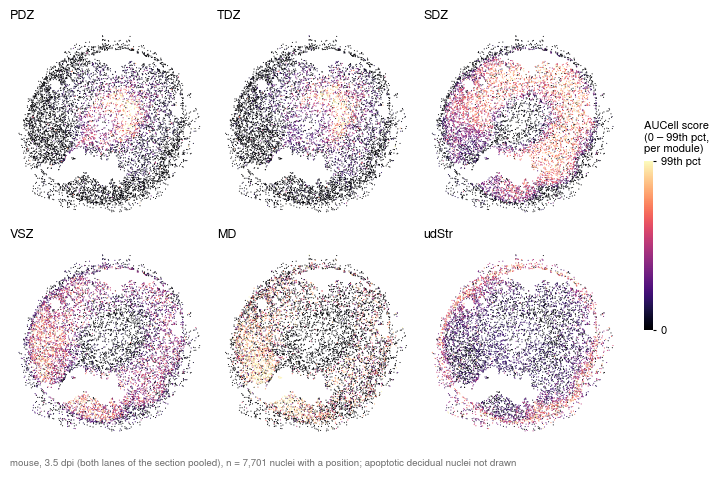

7,701 nuclei drawn; colour ceilings: {'PDZ': 0.345, 'TDZ': 0.284, 'SDZ': 0.317, 'VSZ': 0.228, 'MD': 0.049, 'udStr': 0.245}


In [10]:
def spatial_maps(dark=False):
    fg, bg, grey = colours(dark)
    g = table.dropna(subset=["x_um_qc", "y_um_qc"])
    if DROP_APOPTOTIC_IN_MAPS:
        g = g[g["cell_subtype"] != "decAp"]
    theta = np.deg2rad(ROTATION_DEG)  # rigid rotation for display; both lanes of the section turn together
    dx, dy = g["x_um_qc"] - g["x_um_qc"].median(), g["y_um_qc"] - g["y_um_qc"].median()
    x = (np.cos(theta) * dx - np.sin(theta) * dy).to_numpy()
    y = (np.sin(theta) * dx + np.cos(theta) * dy).to_numpy()
    fig = plt.figure(figsize=(7.2, 4.7), facecolor=bg)
    grid = fig.add_gridspec(2, 3, left=0.01, right=0.86, top=0.95, bottom=0.06, wspace=0.04, hspace=0.1)
    ceilings = {}
    for k, m in enumerate(FOCUS):
        ax = fig.add_subplot(grid[k // 3, k % 3])
        v = g[f"auc_{m}"].to_numpy(float)
        ceilings[m] = float(np.quantile(v, Q))
        shade = np.clip(v / ceilings[m], 0, 1)
        order = np.argsort(shade, kind="stable")  # brightest on top
        ax.scatter(x[order], y[order], c=shade[order], cmap=CMAP, vmin=0, vmax=1, s=0.6, linewidths=0, rasterized=True)
        ax.set_aspect("equal")
        ax.axis("off")
        ax.set_title(m, loc="left", fontsize=9, color=fg)
    colour_bar(fig, fig.add_axes([0.89, 0.3, 0.013, 0.36]), "AUCell score\n(0 \u2013 99th pct,\nper module)", fg)
    note = f"mouse, {TIMEPOINT.replace('_', ' ')} (both lanes of the section pooled), n = {len(g):,} nuclei with a position"
    fig.text(0.01, 0.01, note + ("; apoptotic decidual nuclei not drawn" if DROP_APOPTOTIC_IN_MAPS else ""), fontsize=7, color=grey)
    return fig, ceilings, len(g)


for dark in (False, True):
    fig, spatial_ceilings, n_spatial = spatial_maps(dark)
    save_figure(fig, f"S24B_mouse_zone_module_aucell_spatial_{tag}" + ("_dark" if dark else ""))
    if not dark:
        display(fig)
    plt.close(fig)
print(f"{n_spatial:,} nuclei drawn; colour ceilings:", {m: round(v, 3) for m, v in spatial_ceilings.items()})

### S24A: mean score per subtype

The values drawn are also written as `S24A_heatmap_values_3.5dpi.csv`.

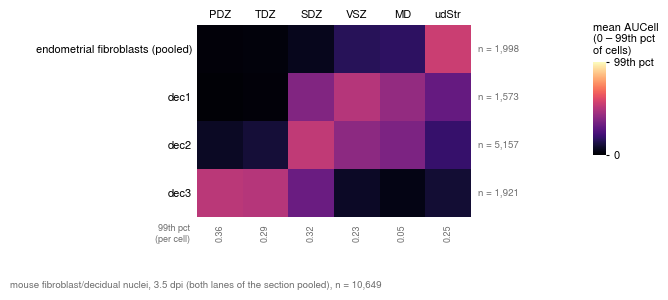

,PDZ,TDZ,SDZ,VSZ,MD,udStr,n
row,,,,,,,
endometrial fibroblasts (pooled),0.0059,0.0062,0.0175,0.0364,0.0084,0.1361,1998.0
dec1,0.0038,0.0047,0.1202,0.1169,0.0204,0.0753,1573.0
dec2,0.0249,0.0302,0.1679,0.0940,0.0178,0.0471,5157.0
dec3,0.1845,0.1449,0.1006,0.0169,0.0017,0.0237,1921.0
99th percentile (colour ceiling),0.3631,0.2920,0.3207,0.2348,0.0491,0.2474,10649.0


In [11]:
rows = {"endometrial fibroblasts (pooled)": table["cell_subtype"].isin(FIBROBLAST_SUBTYPES)}
rows.update({s: table["cell_subtype"] == s for s in DECIDUAL_SUBTYPES})
cols = [f"auc_{m}" for m in FOCUS]
shown = table[table["cell_subtype"].isin(FIBROBLAST_SUBTYPES + DECIDUAL_SUBTYPES)]
heat_ceilings = shown[cols].quantile(Q)  # per module, over every nucleus of the rows shown
means = pd.DataFrame({row: table.loc[mask, cols].mean() for row, mask in rows.items()}).T  # pooled row: cell-weighted
counts = pd.Series({row: int(mask.sum()) for row, mask in rows.items()})


def heatmap(dark=False):
    fg, bg, grey = colours(dark)
    shade = np.clip(means.to_numpy() / heat_ceilings.to_numpy(), 0, 1)
    fig = plt.figure(figsize=(7.2, 3.1), facecolor=bg)
    ax = fig.add_axes([0.27, 0.25, 0.38, 0.62])
    ax.pcolormesh(np.arange(len(FOCUS) + 1) - 0.5, np.arange(len(rows) + 1) - 0.5, shade, cmap=CMAP, vmin=0, vmax=1)
    ax.set_xlim(-0.5, len(FOCUS) - 0.5)
    ax.set_ylim(len(rows) - 0.5, -0.5)  # first row on top
    ax.set_xticks(range(len(FOCUS)), FOCUS, color=fg)
    ax.xaxis.tick_top()
    ax.set_yticks(range(len(rows)), list(rows), color=fg)
    ax.tick_params(length=0, labelsize=8)
    for spine in ax.spines.values():
        spine.set_visible(False)
    for i, row in enumerate(rows):
        ax.text(len(FOCUS) - 0.35, i, f"n = {counts[row]:,}", va="center", ha="left", fontsize=7, color=grey)
    for j, col in enumerate(cols):
        ax.text(j, len(rows) - 0.35, f"{heat_ceilings[col]:.2f}", va="top", ha="center", fontsize=6.5, color=grey, rotation=90)
    ax.text(-0.65, len(rows) - 0.35, "99th pct\n(per cell)", va="top", ha="right", fontsize=6.5, color=grey)
    colour_bar(fig, fig.add_axes([0.82, 0.45, 0.018, 0.3]), "mean AUCell\n(0 \u2013 99th pct\nof cells)", fg)
    fig.text(0.01, 0.02, f"mouse fibroblast/decidual nuclei, {TIMEPOINT.replace('_', ' ')} (both lanes of the section pooled), "
             f"n = {int(counts.sum()):,}", fontsize=7, color=grey)
    return fig


for dark in (False, True):
    fig = heatmap(dark)
    save_figure(fig, f"S24A_mouse_zone_module_aucell_heatmap_{tag}" + ("_dark" if dark else ""))
    if not dark:
        display(fig)
    plt.close(fig)
heat_values = means.rename(columns=lambda c: c[4:]).assign(n=counts)
heat_values.loc["99th percentile (colour ceiling)"] = list(heat_ceilings) + [int(counts.sum())]
heat_values.index.name = "row"
if out:
    heat_values.to_csv(save_path(f"S24A_heatmap_values_{tag}.csv"))
heat_values.round(4)

## Checks, and the numbers the Methods quote

Also written as `S24_numbers.json`.

In [12]:
def same(a, b):
    """Exactly equal score tables: same nuclei, same values."""
    return set(a.index) == set(b.index) and np.array_equal(a.loc[b.index].to_numpy(float), b.to_numpy(float))


stored = [c for c in obs.columns if c.startswith("auc_")]
if stored:
    print(f"scores stored in the object ({len(stored)} modules) equal these:", same(scores[stored], obs.loc[names, stored].astype(float)))
if RECORD_SCORES:
    record = pd.read_csv(RECORD_SCORES, index_col=0, float_precision="round_trip")
    print("published S24 scores equal these:", same(scores[record.columns], record))

numbers = {
    "object": OBJECT, "object_sha256": object_sha256, "nuclei_in_object": n_obs,
    "gene_threshold": f"count > 0 in >= {min_cells} of {n_obs:,} nuclei (1%)", "genes_by_rule": int(by_rule.sum()),
    "table1_genes_added": len(added), "genes_ranked": len(ranked), "auc_window_top_genes": rank_cutoff,
    "share_detecting_fewer_than_window": round(share_below, 4), "nuclei_scored": len(names), "timepoint": TIMEPOINT,
    "seed": SEED, "seed_agreement_spearman": seed_rho,
    "S24B_nuclei_drawn": n_spatial, "S24B_ceilings": {m: round(v, 4) for m, v in spatial_ceilings.items()},
    "S24A_nuclei": int(counts.sum()), "S24A_ceilings": {c[4:]: round(float(v), 4) for c, v in heat_ceilings.items()},
}
if out:
    json.dump(numbers, open(save_path("S24_numbers.json"), "w"), indent=1)
numbers

scores stored in the object (6 modules) equal these: True
published S24 scores equal these: True


{'object': '/n/netscratch/eddy_lab/Everyone/nhilgert/final_objects/Cevrim_XMens_All_Cells.h5ad',
 'object_sha256': 'de53189f98c300e3552685a7cc44e319f6a501f9961ff0c091272ff81f0b00ea',
 'nuclei_in_object': 57033,
 'gene_threshold': 'count > 0 in >= 570 of 57,033 nuclei (1%)',
 'genes_by_rule': 14861,
 'table1_genes_added': 42,
 'genes_ranked': 14903,
 'auc_window_top_genes': 745,
 'share_detecting_fewer_than_window': 0.0953,
 'nuclei_scored': 12324,
 'timepoint': '3.5_dpi',
 'seed': 0,
 'seed_agreement_spearman': {'PDZ': 0.935,
  'TDZ': 0.945,
  'SDZ': 0.989,
  'VSZ': 0.969,
  'MD': 0.94,
  'udStr': 0.974},
 'S24B_nuclei_drawn': 7701,
 'S24B_ceilings': {'PDZ': 0.345,
  'TDZ': 0.284,
  'SDZ': 0.3166,
  'VSZ': 0.2284,
  'MD': 0.0494,
  'udStr': 0.2452},
 'S24A_nuclei': 10649,
 'S24A_ceilings': {'PDZ': 0.3631,
  'TDZ': 0.292,
  'SDZ': 0.3207,
  'VSZ': 0.2348,
  'MD': 0.0491,
  'udStr': 0.2474}}